# **CredScore AI — Modelagem e Resultados (N2)**

**Integrantes:**
- Nome: Rodrigo Daiske Uehara — RA: 10440295

**Síntese do arquivo:** treina e compara três modelos (Regressão Logística, Random Forest e XGBoost)
para prever se um cliente é mau pagador, usando o dataset German Credit Data. Depois avalia os modelos
no conjunto de teste, olha a calibração, explica o melhor modelo com SHAP e compara os erros entre
grupos (sexo e idade).

**Histórico de alterações:**

| Data | Autor | Descrição |
|---|---|---|
| 28/10/2026 | Rodrigo Daiske Uehara | Criação do notebook: carga dos dados, preparação e divisão treino/teste |
| 29/10/2026 | Rodrigo Daiske Uehara | Treino dos três modelos com validação cruzada e busca de hiperparâmetros |
| 30/10/2026 | Rodrigo Daiske Uehara | Métricas no teste, matriz de confusão, custo e calibração |
| 05/11/2026 | Rodrigo Daiske Uehara | SHAP, análise de equidade por sexo e idade e teste sem os atributos sensíveis |
| 06/11/2026 | Rodrigo Daiske Uehara | Revisão dos comentários e exemplo de uso com um cliente novo |

## 1. Bibliotecas e carga dos dados

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             average_precision_score, confusion_matrix,
                             ConfusionMatrixDisplay, brier_score_loss)
from sklearn.calibration import calibration_curve
from xgboost import XGBClassifier
import shap

df = pd.read_csv('../dados/german_credit_data.csv', index_col=0)
print(df.shape)
df.head()

(1000, 10)


,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose,Risk
0,67,male,2,own,NaN,little,1169,6,radio/TV,good
1,22,female,2,own,little,moderate,5951,48,radio/TV,bad
2,49,male,1,own,little,NaN,2096,12,education,good
3,45,male,2,free,little,little,7882,42,furniture/equipment,good
4,53,male,2,free,little,little,4870,24,car,bad


## 2. Preparação dos dados

**Valores ausentes.** No dicionário do dataset original (UCI), a conta corrente tem a categoria
"no checking account" e a poupança tem a categoria "unknown / no savings account". Na versão
simplificada essas categorias viraram valor vazio (NA). Então:

- `Checking account` vazio = cliente **sem conta corrente** (`sem conta`);
- `Saving accounts` vazio = **desconhecido ou sem poupança** (`desconhecido`). Aqui não dá para
  afirmar que é "sem conta", porque o dicionário junta os dois casos.

Por isso os vazios viram uma categoria própria, e não são preenchidos com média ou moda.

In [ ]:
df['Checking account'] = df['Checking account'].fillna('sem conta')
df['Saving accounts'] = df['Saving accounts'].fillna('desconhecido')

# alvo: 1 = mau pagador (bad), 0 = bom pagador (good)
y = (df['Risk'] == 'bad').astype(int)
X = df.drop(columns=['Risk'])

print(y.value_counts())

Risk
0    700
1    300
Name: count, dtype: int64


**Divisão treino/teste.** 70% para treino e 30% para teste, estratificado (mantém 30% de maus
pagadores nos dois). O teste fica guardado e só é usado no final.

In [ ]:
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y)

print('Treino:', X_treino.shape, '| maus pagadores:', y_treino.sum())
print('Teste :', X_teste.shape, '| maus pagadores:', y_teste.sum())

Treino: (700, 9) | maus pagadores: 210
Teste : (300, 9) | maus pagadores: 90


**Pré-processamento dentro do Pipeline.** As colunas numéricas são padronizadas e as categóricas
viram colunas 0/1 (one-hot). Tudo fica dentro de um `Pipeline` junto com o modelo. Assim, na
validação cruzada, a padronização e a codificação são ajustadas só com a parte de treino de cada
partição, e não tem vazamento de dados.

In [ ]:
colunas_num = ['Age', 'Job', 'Credit amount', 'Duration']
colunas_cat = ['Sex', 'Housing', 'Saving accounts', 'Checking account', 'Purpose']

def cria_preprocessamento(num, cat):
    return ColumnTransformer([
        ('num', StandardScaler(), num),
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat)
    ])

## 3. Treino dos modelos

- **Validação cruzada:** 5 partições estratificadas, só no conjunto de treino.
- **Hiperparâmetros:** `GridSearchCV` com uma grade pequena para cada modelo, escolhendo pelo F1 da
  classe mau pagador.
- **Desbalanceamento:** peso de classe (`class_weight='balanced'` e, no XGBoost, `scale_pos_weight`).
  Não foi usado SMOTE porque a maioria das colunas é categórica, e o SMOTE comum cria exemplos
  fazendo média entre vizinhos, o que não faz sentido para categorias. O peso de classe não cria
  dado novo, só faz o erro no mau pagador valer mais.

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# quantos bons pagadores existem para cada mau pagador no treino (usado no XGBoost)
peso_mau = (y_treino == 0).sum() / (y_treino == 1).sum()
print('Peso da classe mau pagador:', round(peso_mau, 2))

modelos = {
    'Regressão Logística': (
        LogisticRegression(class_weight='balanced', max_iter=1000),
        {'modelo__C': [0.01, 0.1, 1, 10]}
    ),
    'Random Forest': (
        RandomForestClassifier(class_weight='balanced', random_state=42),
        {'modelo__n_estimators': [100, 300],
         'modelo__max_depth': [3, 5, None],
         'modelo__min_samples_leaf': [1, 5]}
    ),
    'XGBoost': (
        XGBClassifier(scale_pos_weight=peso_mau, random_state=42),
        {'modelo__n_estimators': [100, 300],
         'modelo__max_depth': [2, 3, 4],
         'modelo__learning_rate': [0.05, 0.1]}
    ),
}

Peso da classe mau pagador: 2.33


In [ ]:
treinados = {}
linhas = []

for nome, (modelo, grade) in modelos.items():
    pipe = Pipeline([
        ('prep', cria_preprocessamento(colunas_num, colunas_cat)),
        ('modelo', modelo)
    ])
    busca = GridSearchCV(pipe, grade, cv=cv, scoring='f1')
    busca.fit(X_treino, y_treino)
    treinados[nome] = busca.best_estimator_

    i = busca.best_index_
    linhas.append({
        'Modelo': nome,
        'F1 médio (validação cruzada)': round(busca.cv_results_['mean_test_score'][i], 3),
        'Desvio padrão': round(busca.cv_results_['std_test_score'][i], 3),
        'Melhores hiperparâmetros': busca.best_params_
    })

pd.set_option('display.max_colwidth', None)
tabela_cv = pd.DataFrame(linhas)
tabela_cv

,Modelo,F1 médio (validação cruzada),Desvio padrão,Melhores hiperparâmetros
0,Regressão Logística,0.553,0.035,{'modelo__C': 0.1}
1,Random Forest,0.584,0.061,"{'modelo__max_depth': 5, 'modelo__min_samples_leaf': 5, 'modelo__n_estimators': 300}"
2,XGBoost,0.585,0.046,"{'modelo__learning_rate': 0.05, 'modelo__max_depth': 2, 'modelo__n_estimators': 300}"


Os três modelos ficaram bem próximos na validação cruzada, e a diferença entre eles é menor que o
desvio padrão. O XGBoost teve o maior F1 médio, então ele foi escolhido como modelo final **antes**
de olhar o conjunto de teste.

## 4. Avaliação no conjunto de teste

Além dos três modelos, tem uma baseline que sempre responde "bom pagador" (a classe mais comum).

**Custo do erro.** A documentação do dataset original traz uma matriz de custo: aprovar um mau
pagador custa 5 e negar um bom pagador custa 1. Então `custo = 5 x FN + 1 x FP`.

In [ ]:
baseline = DummyClassifier(strategy='most_frequent')
baseline.fit(X_treino, y_treino)

def avalia(nome, modelo):
    pred = modelo.predict(X_teste)
    prob = modelo.predict_proba(X_teste)[:, 1]
    tn, fp, fn, tp = confusion_matrix(y_teste, pred).ravel()
    return {
        'Modelo': nome,
        'Acurácia': round(accuracy_score(y_teste, pred), 3),
        'Precisão': round(precision_score(y_teste, pred, zero_division=0), 3),
        'Recall': round(recall_score(y_teste, pred), 3),
        'F1': round(f1_score(y_teste, pred), 3),
        'PR-AUC': round(average_precision_score(y_teste, prob), 3),
        'FN': fn, 'FP': fp,
        'Custo (5xFN + FP)': 5 * fn + fp
    }

resultados = [avalia('Baseline (sempre bom pagador)', baseline)]
for nome, modelo in treinados.items():
    resultados.append(avalia(nome, modelo))

tabela_teste = pd.DataFrame(resultados)
tabela_teste.to_csv('../resultados/metricas_teste.csv', index=False)
tabela_teste

,Modelo,Acurácia,Precisão,Recall,F1,PR-AUC,FN,FP,Custo (5xFN + FP)
0,Baseline (sempre bom pagador),0.700,0.000,0.000,0.000,0.300,90,0,450
1,Regressão Logística,0.700,0.500,0.722,0.591,0.623,25,65,190
2,Random Forest,0.700,0.500,0.744,0.598,0.599,23,67,182
3,XGBoost,0.723,0.529,0.711,0.607,0.589,26,57,187


A baseline tem 70% de acurácia sem encontrar nenhum mau pagador (recall 0), o que mostra por que a
acurácia sozinha engana nessa base. Negar todo mundo custaria 210 (210 bons pagadores negados) e
aprovar todo mundo custaria 450 (90 maus pagadores x 5).

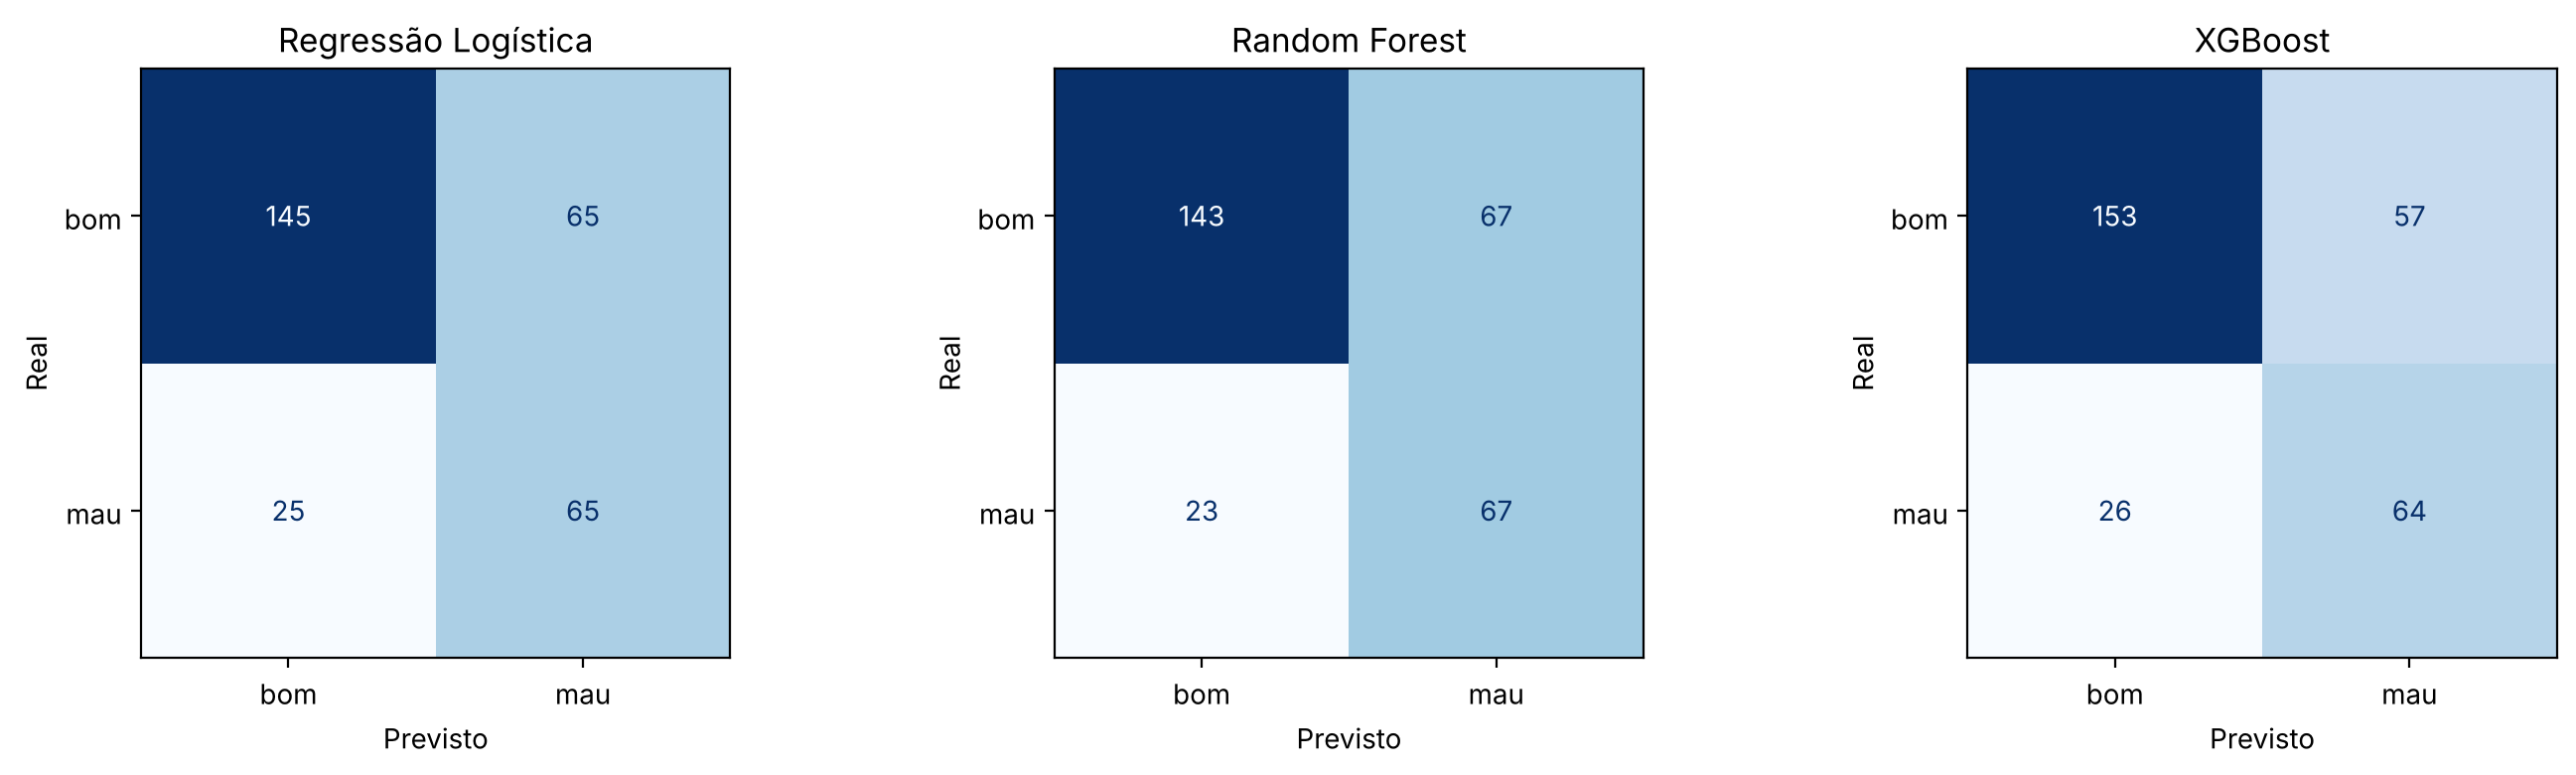

In [ ]:
fig, eixos = plt.subplots(1, 3, figsize=(14, 4))
for eixo, (nome, modelo) in zip(eixos, treinados.items()):
    ConfusionMatrixDisplay.from_estimator(
        modelo, X_teste, y_teste, display_labels=['bom', 'mau'],
        cmap='Blues', colorbar=False, ax=eixo)
    eixo.set_title(nome)
    eixo.set_xlabel('Previsto')
    eixo.set_ylabel('Real')
plt.tight_layout()
plt.savefig('../resultados/fig_matrizes_confusao.png', dpi=150)
plt.show()

## 5. Calibração

A calibração verifica se a probabilidade que o modelo dá bate com a realidade (por exemplo, de
todos os clientes que receberam 70%, perto de 70% deveriam ser maus pagadores).

Critérios usados: a curva deve ficar perto da diagonal e o **Brier score** deve ser o menor possível
(0 é perfeito). Um modelo que respondesse sempre 30% teria Brier de 0,21.

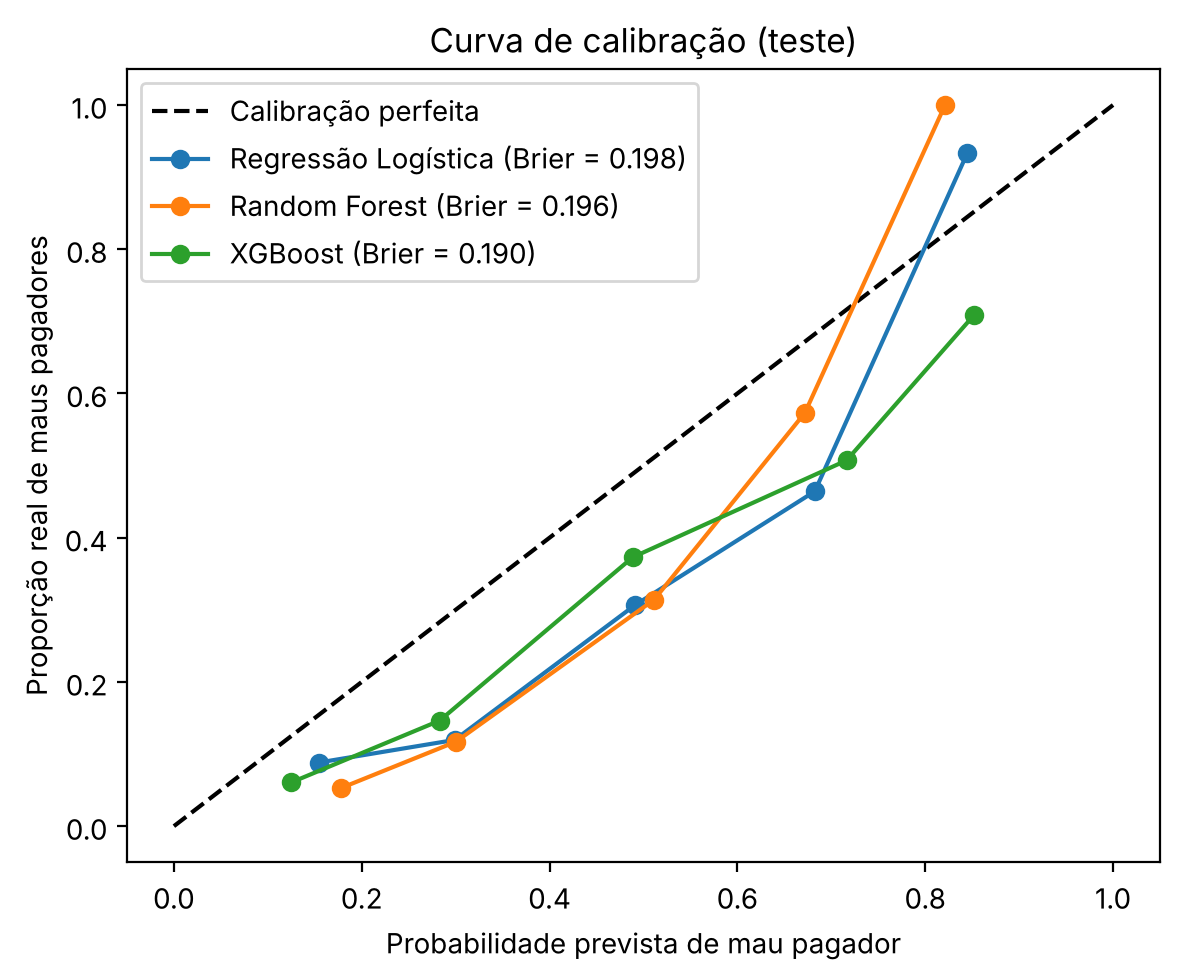

Brier de quem sempre responde 30%: 0.21


In [ ]:
plt.figure(figsize=(6, 5))
plt.plot([0, 1], [0, 1], 'k--', label='Calibração perfeita')

for nome, modelo in treinados.items():
    prob = modelo.predict_proba(X_teste)[:, 1]
    fracao_real, media_prevista = calibration_curve(y_teste, prob, n_bins=5)
    brier = brier_score_loss(y_teste, prob)
    plt.plot(media_prevista, fracao_real, marker='o', label=f'{nome} (Brier = {brier:.3f})')

plt.xlabel('Probabilidade prevista de mau pagador')
plt.ylabel('Proporção real de maus pagadores')
plt.title('Curva de calibração (teste)')
plt.legend()
plt.tight_layout()
plt.savefig('../resultados/fig_calibracao.png', dpi=150)
plt.show()

print('Brier de quem sempre responde 30%:', round(brier_score_loss(y_teste, np.full(len(y_teste), 0.3)), 3))

Quase todos os pontos ficam abaixo da diagonal (a curva do XGBoost fica inteira abaixo): os modelos
dão probabilidades mais altas do que o real. Isso é esperado, porque o peso de classe faz o modelo
"exagerar" o risco para não deixar passar mau pagador. O Brier dos três (0,19 a 0,20) é só um pouco
melhor que 0,21. Então a saída serve para separar os clientes, mas não deve ser lida como a chance
exata de inadimplência.

## 6. Explicabilidade com SHAP (modelo final: XGBoost)

O SHAP mostra quanto cada variável empurrou a previsão para "mau pagador" (valor positivo) ou para
"bom pagador" (valor negativo).

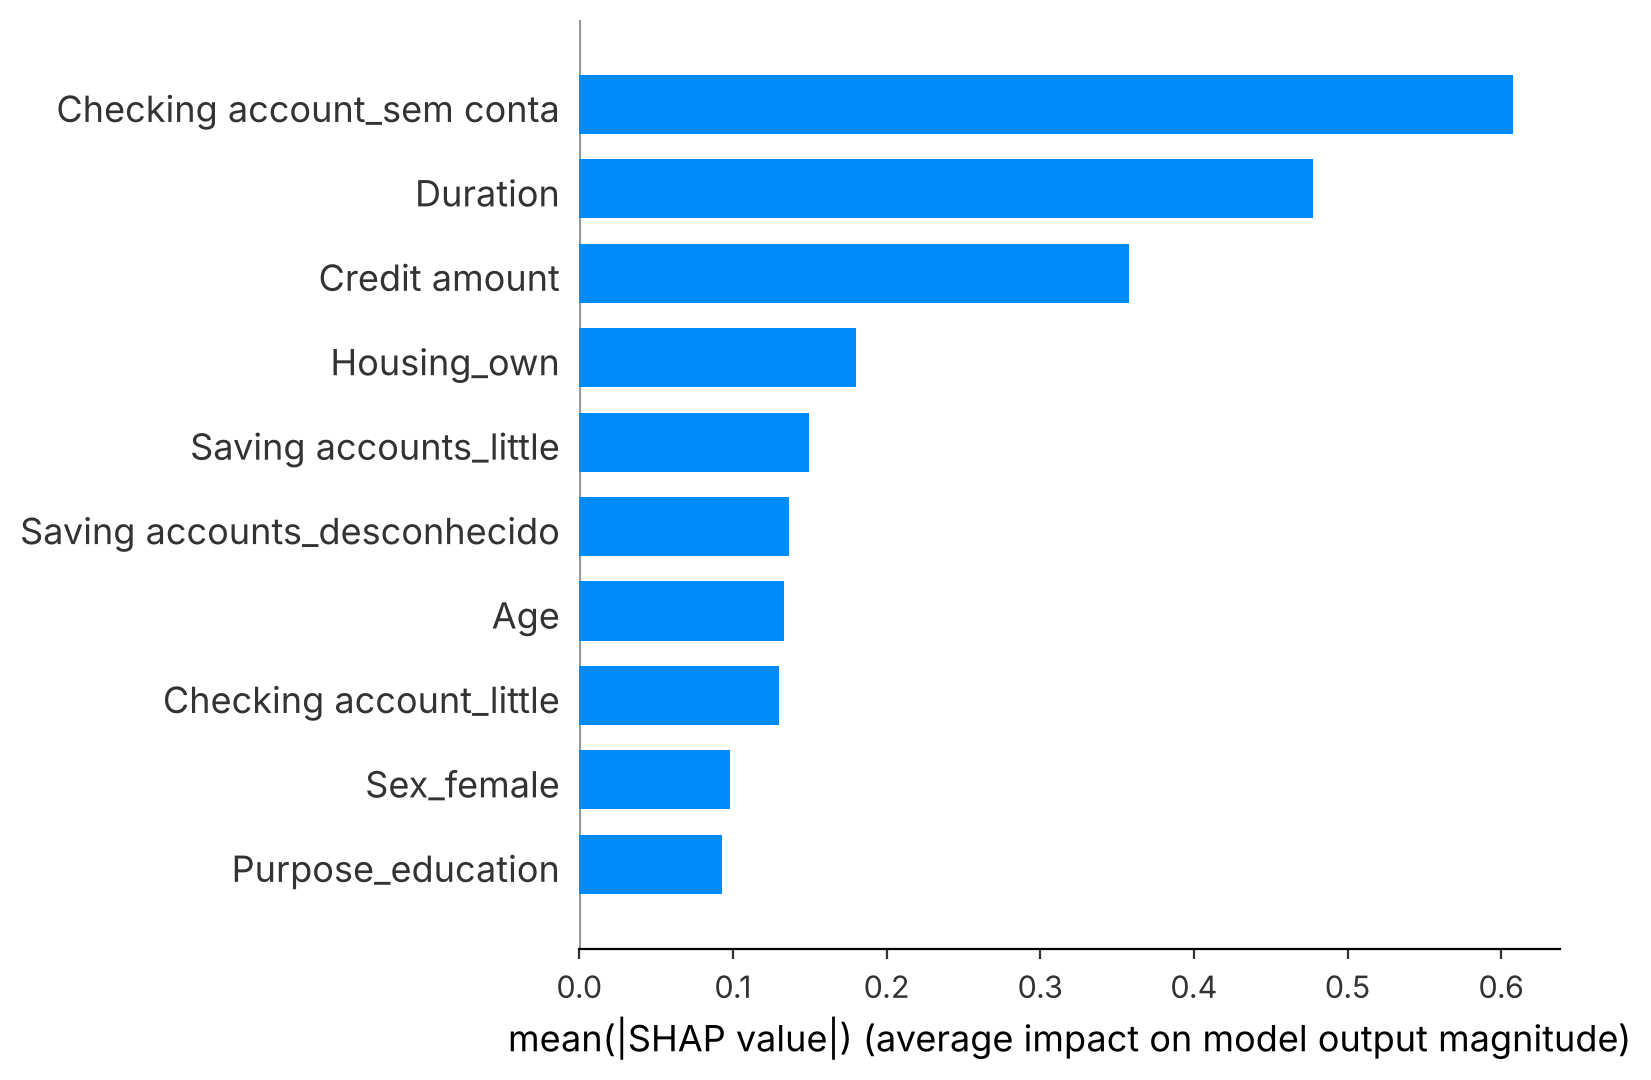

In [ ]:
modelo_final = treinados['XGBoost']
prep = modelo_final.named_steps['prep']
xgb = modelo_final.named_steps['modelo']

# dados de teste já transformados, com o nome de cada coluna
nomes = [n.replace('num__', '').replace('cat__', '') for n in prep.get_feature_names_out()]
X_teste_t = pd.DataFrame(prep.transform(X_teste), columns=nomes)

explicador = shap.TreeExplainer(xgb)
valores_shap = explicador.shap_values(X_teste_t)

shap.summary_plot(valores_shap, X_teste_t, plot_type='bar', max_display=10, show=False)
plt.tight_layout()
plt.savefig('../resultados/fig_shap_importancia.png', dpi=150)
plt.show()

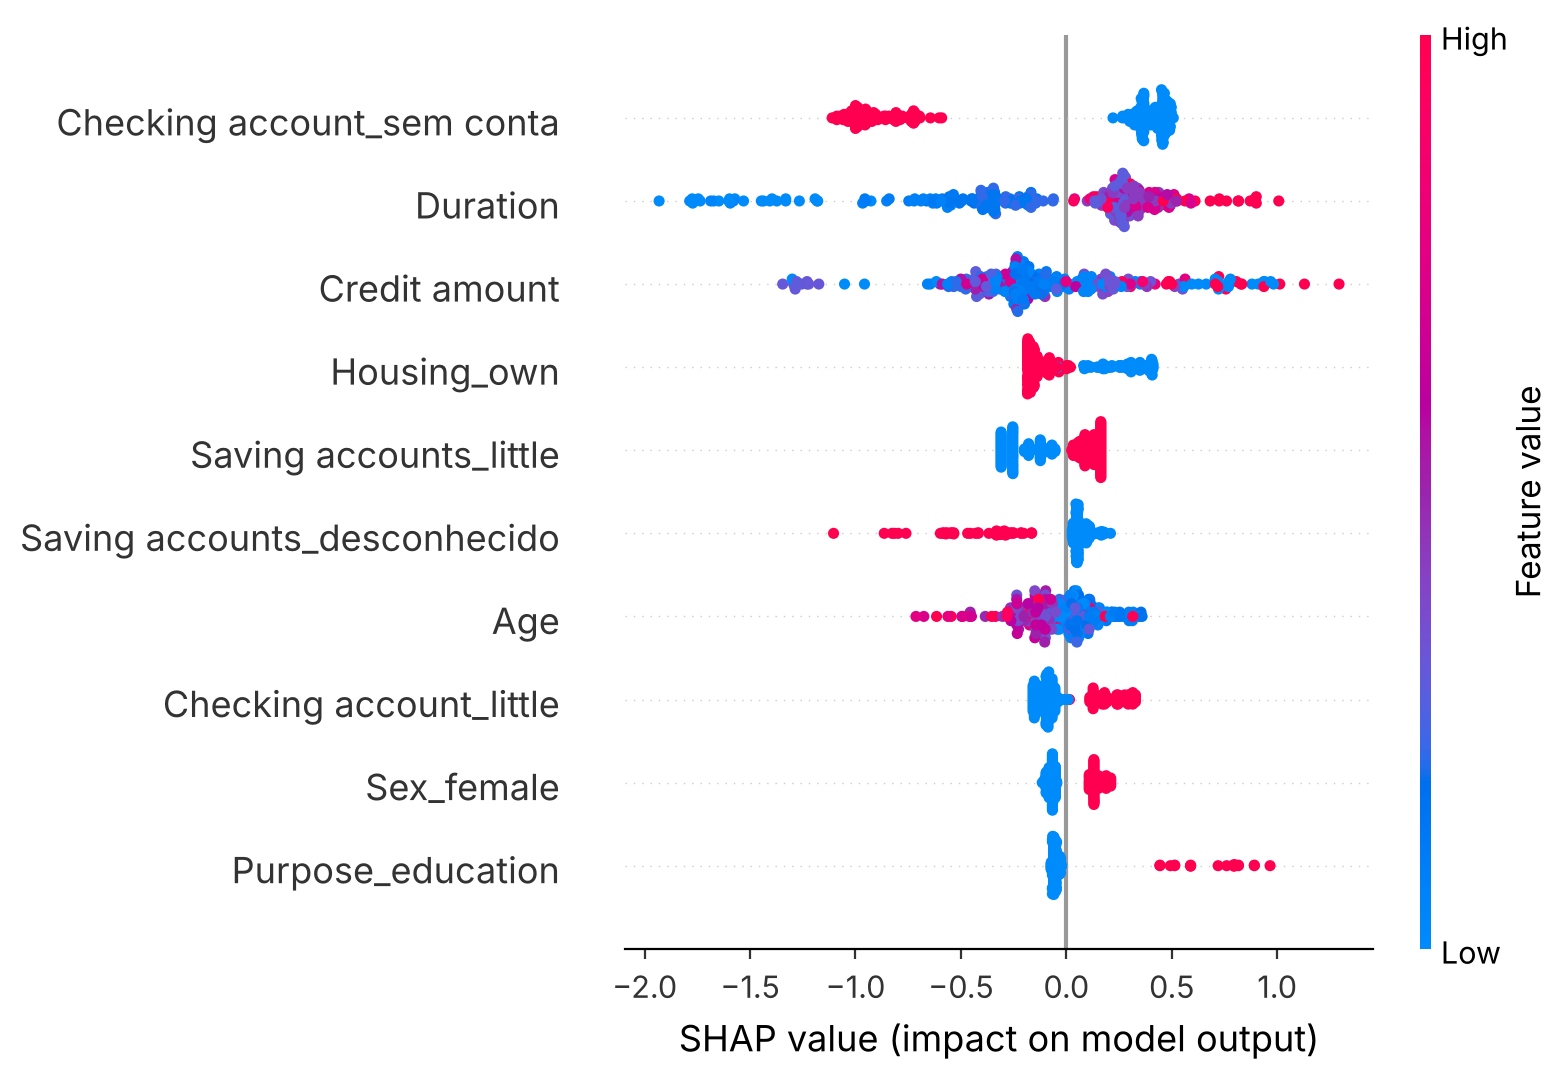

In [ ]:
shap.summary_plot(valores_shap, X_teste_t, max_display=10, show=False)
plt.tight_layout()
plt.savefig('../resultados/fig_shap_resumo.png', dpi=150)
plt.show()

In [ ]:
# importância média de cada variável (em tabela)
importancia = pd.Series(np.abs(valores_shap).mean(axis=0), index=nomes).sort_values(ascending=False)
importancia.round(3).head(10)

Checking account_sem conta      0.608
Duration                        0.477
Credit amount                   0.358
Housing_own                     0.180
Saving accounts_little          0.150
Saving accounts_desconhecido    0.137
Age                             0.134
Checking account_little         0.130
Sex_female                      0.098
Purpose_education               0.093
dtype: float32

## 7. Equidade entre grupos

Aqui a comparação é pelos **erros do modelo** em cada grupo, e não pela proporção de maus pagadores:

- **TPR (recall):** dos maus pagadores do grupo, quantos o modelo encontrou;
- **FPR:** dos bons pagadores do grupo, quantos o modelo negou por engano.

Como os grupos são pequenos, cada taxa vem com um intervalo de confiança de 95%
(`p ± 1,96 x raiz(p x (1 - p) / n)`).

Critério definido: a diferença de TPR e de FPR entre os grupos deveria ser de no máximo 0,10.

Faixas de idade: até 25 anos e acima de 25 (com mais faixas os grupos ficariam pequenos demais no
teste).

In [ ]:
def taxa_com_ic(acertos, total):
    p = acertos / total
    margem = 1.96 * np.sqrt(p * (1 - p) / total)
    return p, max(p - margem, 0), min(p + margem, 1)

def equidade(modelo, X_teste_modelo):
    pred = modelo.predict(X_teste_modelo)
    dados = X_teste.copy()            # sempre usa o teste completo para saber o grupo
    dados['real'] = y_teste.values
    dados['pred'] = pred
    dados['Idade'] = np.where(dados['Age'] <= 25, 'até 25 anos', 'acima de 25')

    linhas = []
    for coluna in ['Sex', 'Idade']:
        for grupo in sorted(dados[coluna].unique()):
            g = dados[dados[coluna] == grupo]
            maus = g[g['real'] == 1]
            bons = g[g['real'] == 0]
            tpr, tpr_min, tpr_max = taxa_com_ic((maus['pred'] == 1).sum(), len(maus))
            fpr, fpr_min, fpr_max = taxa_com_ic((bons['pred'] == 1).sum(), len(bons))
            linhas.append({
                'Atributo': coluna, 'Grupo': grupo, 'Clientes': len(g),
                'Maus': len(maus), 'Bons': len(bons),
                'TPR': round(tpr, 3), 'IC 95% TPR': f'{tpr_min:.2f} a {tpr_max:.2f}',
                'FPR': round(fpr, 3), 'IC 95% FPR': f'{fpr_min:.2f} a {fpr_max:.2f}'
            })
    return pd.DataFrame(linhas)

tabela_equidade = equidade(modelo_final, X_teste)
tabela_equidade.to_csv('../resultados/equidade.csv', index=False)
tabela_equidade

,Atributo,Grupo,Clientes,Maus,Bons,TPR,IC 95% TPR,FPR,IC 95% FPR
0,Sex,female,101,35,66,0.714,0.56 a 0.86,0.318,0.21 a 0.43
1,Sex,male,199,55,144,0.709,0.59 a 0.83,0.250,0.18 a 0.32
2,Idade,acima de 25,234,60,174,0.733,0.62 a 0.85,0.259,0.19 a 0.32
3,Idade,até 25 anos,66,30,36,0.667,0.50 a 0.84,0.333,0.18 a 0.49


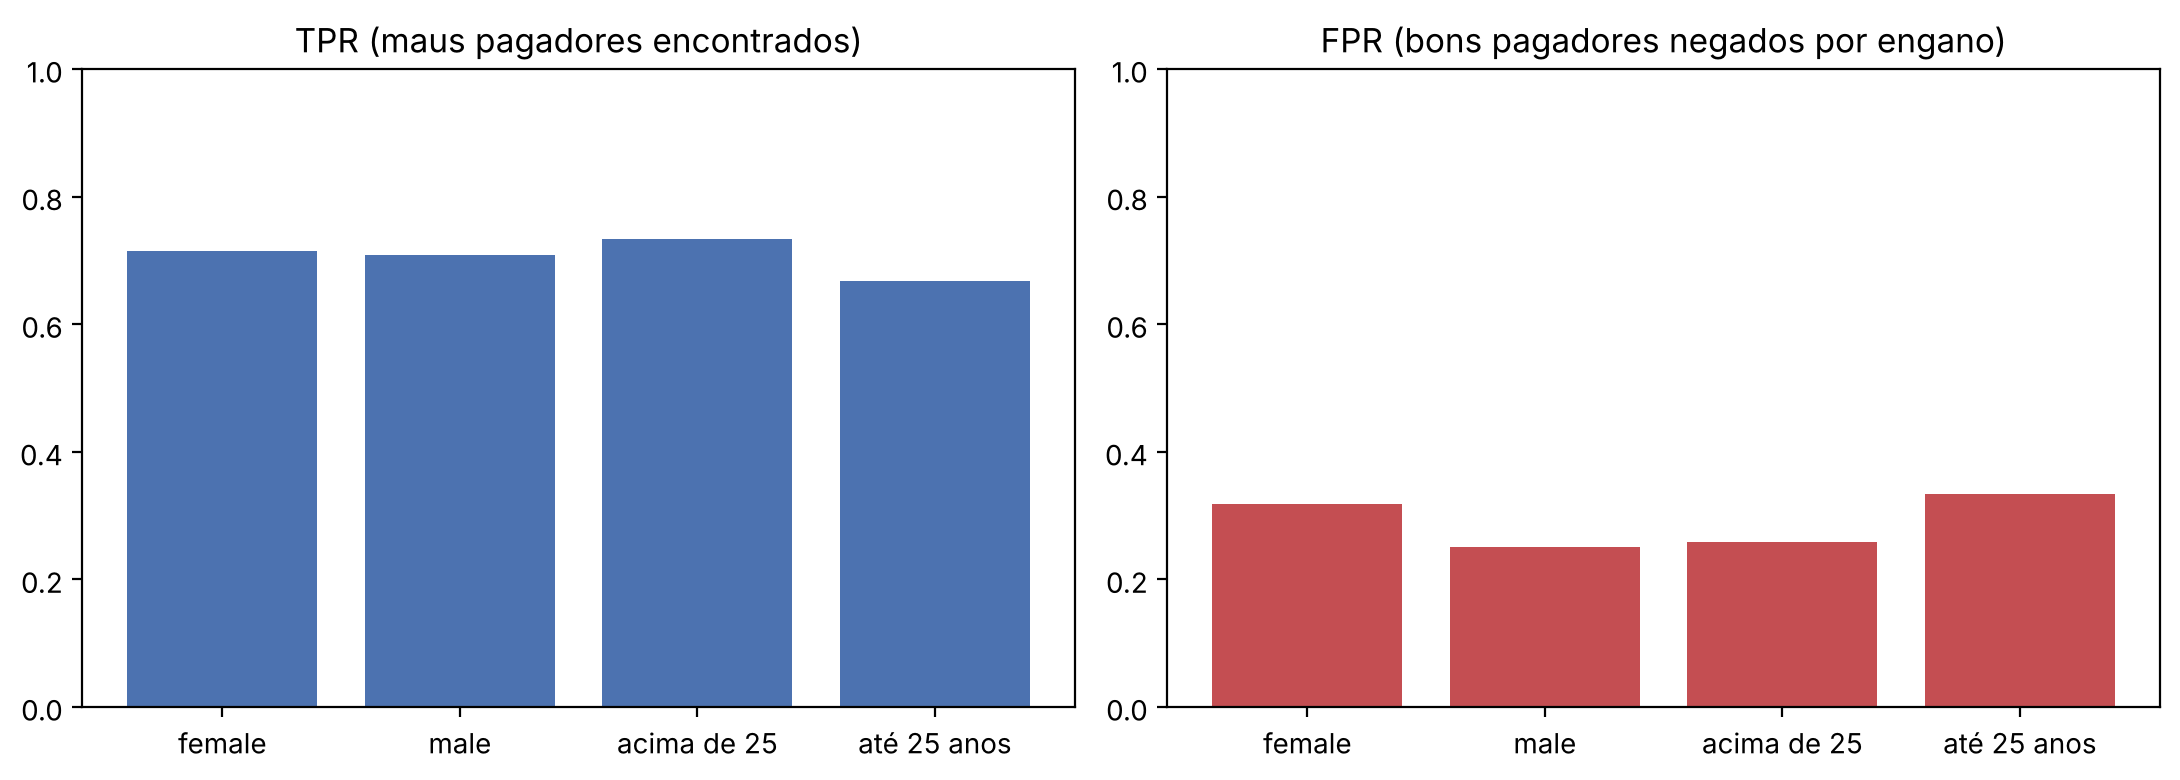

In [ ]:
fig, eixos = plt.subplots(1, 2, figsize=(11, 4))
rotulos = tabela_equidade['Grupo']
eixos[0].bar(rotulos, tabela_equidade['TPR'], color='#4C72B0')
eixos[0].set_title('TPR (maus pagadores encontrados)')
eixos[1].bar(rotulos, tabela_equidade['FPR'], color='#C44E52')
eixos[1].set_title('FPR (bons pagadores negados por engano)')
for eixo in eixos:
    eixo.set_ylim(0, 1)
plt.tight_layout()
plt.savefig('../resultados/fig_equidade.png', dpi=150)
plt.show()

### 7.1. Teste: treinar sem sexo e idade

Uma medida simples para tentar diminuir a diferença é tirar `Sex` e `Age` do modelo. O teste abaixo
treina o mesmo XGBoost (mesmos hiperparâmetros) sem essas duas colunas e compara.

In [ ]:
num_sem = ['Job', 'Credit amount', 'Duration']
cat_sem = ['Housing', 'Saving accounts', 'Checking account', 'Purpose']

modelo_sem = Pipeline([
    ('prep', cria_preprocessamento(num_sem, cat_sem)),
    ('modelo', XGBClassifier(**xgb.get_params()))
])
modelo_sem.fit(X_treino[num_sem + cat_sem], y_treino)

pred_sem = modelo_sem.predict(X_teste[num_sem + cat_sem])
tn, fp, fn, tp = confusion_matrix(y_teste, pred_sem).ravel()
print('Sem sexo e idade -> Recall:', round(recall_score(y_teste, pred_sem), 3),
      '| F1:', round(f1_score(y_teste, pred_sem), 3),
      '| Custo:', 5 * fn + fp)

tabela_equidade_sem = equidade(modelo_sem, X_teste[num_sem + cat_sem])
tabela_equidade_sem.to_csv('../resultados/equidade_sem_sexo_idade.csv', index=False)
tabela_equidade_sem

Sem sexo e idade -> Recall: 0.711 | F1: 0.604 | Custo: 188


,Atributo,Grupo,Clientes,Maus,Bons,TPR,IC 95% TPR,FPR,IC 95% FPR
0,Sex,female,101,35,66,0.686,0.53 a 0.84,0.288,0.18 a 0.40
1,Sex,male,199,55,144,0.727,0.61 a 0.84,0.271,0.20 a 0.34
2,Idade,acima de 25,234,60,174,0.750,0.64 a 0.86,0.264,0.20 a 0.33
3,Idade,até 25 anos,66,30,36,0.633,0.46 a 0.81,0.333,0.18 a 0.49


## 8. Exemplo de uso com um cliente novo

Para mostrar o modelo funcionando: informa os dados de um cliente e o modelo responde a
classificação. A decisão final continuaria sendo de uma pessoa.

In [ ]:
cliente = pd.DataFrame([{
    'Age': 23, 'Sex': 'female', 'Job': 2, 'Housing': 'rent',
    'Saving accounts': 'little', 'Checking account': 'little',
    'Credit amount': 6000, 'Duration': 36, 'Purpose': 'car'
}])

prob = modelo_final.predict_proba(cliente)[0, 1]
classe = 'MAU pagador (risco alto)' if prob >= 0.5 else 'BOM pagador (risco baixo)'
print(f'Pontuação de risco do modelo: {prob:.2f}')
print('Classificação:', classe)

Pontuação de risco do modelo: 0.79
Classificação: MAU pagador (risco alto)


In [ ]:
cliente2 = pd.DataFrame([{
    'Age': 45, 'Sex': 'male', 'Job': 2, 'Housing': 'own',
    'Saving accounts': 'rich', 'Checking account': 'sem conta',
    'Credit amount': 1500, 'Duration': 12, 'Purpose': 'radio/TV'
}])

prob2 = modelo_final.predict_proba(cliente2)[0, 1]
classe2 = 'MAU pagador (risco alto)' if prob2 >= 0.5 else 'BOM pagador (risco baixo)'
print(f'Pontuação de risco do modelo: {prob2:.2f}')
print('Classificação:', classe2)

Pontuação de risco do modelo: 0.06
Classificação: BOM pagador (risco baixo)


## 9. Conclusões

- Os três modelos tiveram desempenho parecido. O XGBoost foi escolhido por ter o maior F1 médio na
  validação cruzada 0,585, mas a diferença para o Random Forest 0,584 é mínima.
- No teste, o XGBoost encontrou 71,1% dos maus pagadores recall 0,711, com F1 de 0,607 e PR-AUC de
  0,589. A meta de recall de pelo menos 0,70 foi atingida, por pouco.
- O custo do XGBoost foi 187, menor que negar todo mundo 210 e que aprovar todo mundo 450. No
  teste, o Random Forest teve custo um pouco menor 182 e a Regressão Logística teve o maior PR-AUC
  0,623, o que confirma que nenhum modelo é claramente melhor.
- O modelo ainda erra bastante: 57 dos 210 bons pagadores do teste seriam negados por engano.
- As probabilidades saem exageradas, por causa do peso de classe.
- Pelo SHAP, as variáveis que mais pesam são a conta corrente, o prazo e o valor do crédito.
- As diferenças de TPR e FPR entre sexos e entre faixas de idade ficaram abaixo de 0,10, mas os
  intervalos de confiança são largos, então não dá para afirmar que o modelo é justo.
- Tirar sexo e idade não melhorou a equidade: a diferença de TPR por idade foi de 0,067 para 0,117.